# K1足球坐标静态只读测试

目的：Ball框 → 深度与内参 → 相机三维球心 → get_transform → trunk候选坐标。

保持机器人、头部和球静止。本程序只查询数据，不发送头部、身体、模式或踢球命令。无需教师JSON。

默认深度比例0.001只是毫米候选假设；同像素配准和深度表示光轴Z也需现场核对。计算成功仍是候选值。


In [1]:
from pathlib import Path
from probe_ball_coordinates import run_probe


## 填写本次参数

先把一颗球放在视野内。`KNOWN_XY=None`可先观察坐标；知道trunk原点和轴向后再填写卷尺值。

现有detector应为soccer模型；如果不是，将下一格的DETECTOR设为None，由工具创建足球检测器。


In [2]:
DEPTH_SCALE_M = 0.001    # 待核对的米/原始深度单位，不能靠dtype确认
KNOWN_XY = None           # 可选：(实测x, 实测y)，单位米，使用本次目标帧原点
BALL_RADIUS_M = None      # 可选：实测足球半径，单位米
NOTE = "正前方静止球"    # 每次改为本次位置和观察情况
OUTPUT_ROOT = "足球坐标测试结果"

ROBOT = globals().get("robot")
DETECTOR = globals().get("detector")


## 采集一次并计算

复用已有robot/detector；未传入时由模块创建并缓存。先取RGB、深度和TF，后执行检测。

结束时打印记录目录与ZIP，错误时也保存已有数据。本次检测可能耗时约数秒。


In [3]:
report = run_probe(
    robot=ROBOT, detector=DETECTOR,
    depth_scale_m=DEPTH_SCALE_M, known_xy=KNOWN_XY,
    ball_radius_m=BALL_RADIUS_M, note=NOTE, output_root=OUTPUT_ROOT,
)


静态只读测试：不发送动作。深度比例、同像素配准及光轴Z均按假设记录。


[Booster OS] [boosteros.sdk] [INFO] SDK Channel initialized on default
[Booster OS] [boosteros.sdk] [INFO] Starting Booster SDK Local Adapter (mode=local, network_interface=default, virtual_robot_name=default).
[Booster OS] [boosteros.sdk] [INFO] Booster SDK Local Adapter started (mode=local, network_interface=default).


Network interface not specified. Will use environment variable (FASTRTPS_DEFAULT_PROFILES_FILE).
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024


[Booster OS] [boosteros.robot] [INFO] Fetching camera configuration from API...
[Booster OS] [boosteros.robot] [INFO] Using cameras ['head'] from API, default camera is 'head'.
[Booster OS] [boosteros.BoosterHandGuidingManager] [INFO] BoosterHandGuidingManager initialized with default_record_file=/opt/booster/Gait/bin/joint_position.txt, record_archive_dir=~/.boosteros/hand_guiding
[Booster OS] [boosteros.ros] [INFO] [/boosteros_ros2_adapter_0ae79715] Booster ROS 2 Adapter initialized. Cameras: head(rgb=/boostercamera/head/rgb, depth=/boostercamera/head/depth). Default camera: head.
[Booster OS] [boosteros.ros] [INFO] [/boosteros_ros2_adapter_0ae79715] Booster ROS 2 Adapter started with 4 threads.
[Booster OS] [boosteros.robot] [INFO] Initializing audio manager & speech runtime...


ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024


[Booster OS] [boosteros.BoosterAudioManager] [INFO] _BoosterAudioRuntime initialized
[Booster OS] [boosteros.BoosterAudioManager] [INFO] BoosterAudioManager initialized
[Booster OS] [boosteros.BoosterSpeechRuntime] [INFO] Booster speech runtime initialized for robot_name=''
[Booster OS] [boosteros.robot] [INFO] Booster OS resources initialized.


ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024
ChannelSubscriber::InitChannel: setting reliability: 1, queue_capacity: 1024


[Booster OS] [boosteros.brain.vision.detection] [INFO] Found model in package: /usr/local/lib/python3.10/dist-packages/boosteros/brain/res/all.onnx
[Booster OS] [boosteros.brain.vision.detection] [INFO] Initializing LocalYoloDetector with model: /usr/local/lib/python3.10/dist-packages/boosteros/brain/res/all.onnx
[Booster OS] [boosteros.brain.vision.detection] [INFO] Pre-loading YOLO model to default device...


Loading /usr/local/lib/python3.10/dist-packages/boosteros/brain/res/all.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.23.2 CPUExecutionProvider
TF请求： head_color_optical_frame → trunk 
 [[ -0.0054519   -0.017064     0.99984    0.075155]
 [   -0.99998  0.00092919  -0.0054369    0.040436]
 [-0.00083627    -0.99985   -0.017068     0.34154]
 [          0           0           0           1]]
检测： {'class_name': 'Ball', 'confidence': 0.8655524849891663, 'bbox': [289, 263, 19, 18], 'distance_m': None}
候选球心[trunk]：x=+3.072, y=-0.207, z=-0.526 m
拟合半径=0.241 m，球面RMS=0.1149 m
记录目录： /home/booster/Workspace/X_C/K1足球坐标_测试工具包/足球坐标测试结果/球位_20261103_113057_624030 
结果ZIP： /home/booster/Workspace/X_C/K1足球坐标_测试工具包/足球坐标测试结果/球位_20261103_113057_624030.zip


## 核对选中的球与数值

`candidate_only`表示候选值已经算出，不代表已可供踢球控制。

将球移到左侧、右侧或向前移动卷尺量得的距离，停稳后修改NOTE并重运行参数格和采集格。比较左右符号及前后差值；球位变化时，机器人与头部保持不动。


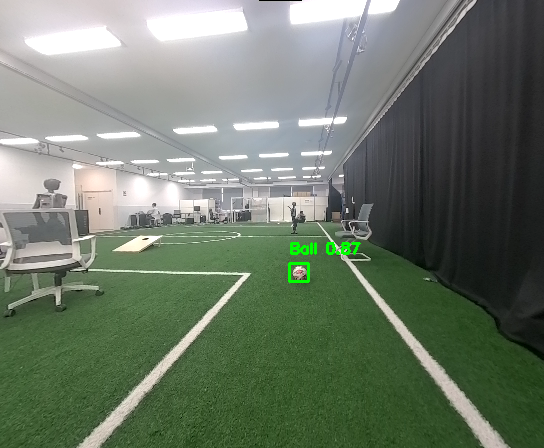

{'状态': 'candidate_only',
 '候选球心[x,y,z]米': [3.0721017051742265,
  -0.20694906264976892,
  -0.5257151801287017],
 '球面拟合': {'ellipse_pixels': 134,
  'valid_points': 134,
  'invalid_raw_hypothesis': [0, 65535],
  'raw_median': 2946.5,
  'raw_min': 2530.0,
  'raw_max': 3601.0,
  'center_camera_m': [0.2317677847189663,
   0.8157564479013547,
   3.012613863908623],
  'fitted_radius_m': 0.24063112873981507,
  'sphere_rms_m': 0.11486492714198904,
  'surface_sample_median_camera_m': [0.26149476977564295,
   0.8164096733658336,
   2.9465],
  'sampled_points': 134,
  'singular_values': [11.607340393569087,
   5.337057431415687,
   1.1141643208948244,
   0.2567857891082777]},
 '卷尺比较': None,
 'RGB/深度时间差秒': 0.0,
 'TF/RGB时间差秒': 1.069342851638794,
 '检测耗时秒': 1.926035481999861,
 '提示': ['TF与RGB时间差超过0.12秒；保持静止核对，不能延伸为运动时有效', '球面半径或残差异常；候选值可能取到背景，须检查原图与深度'],
 '异常': None}

In [4]:
from IPython.display import display, Image as DisplayImage

folder = Path(report["output_dir"])
picture = folder / "selected_ball.png"
if not picture.exists():
    picture = folder / "rgb.png"
if picture.exists():
    display(DisplayImage(filename=str(picture)))

display({
    "状态": report["status"],
    "候选球心[x,y,z]米": report["candidate_center_target_m"],
    "球面拟合": report.get("sphere_fit"),
    "卷尺比较": report.get("measurement_comparison"),
    "RGB/深度时间差秒": report.get("rgb_depth_skew_s"),
    "TF/RGB时间差秒": report.get("transform", {}).get("tf_minus_rgb_s"),
    "检测耗时秒": report.get("detection_elapsed_s"),
    "提示": report["warnings"],
    "异常": report.get("error"),
})


若需要回读分析，保留并反馈本次ZIP即可。它包含原图、原单位深度、内参、矩阵、计算结果和异常。

trunk候选坐标与SoccerKickManager当前控制身体坐标的关系仍需确认。当前静态测试不会将结果传入update_ball，也不承担运动中的时延补偿。
